# 04 · EMT-TF Expression — Cohen et al. 2021 Multiple Myeloma

The unconditional expression step (the final notebook; Gate 2 passed as non-branching, so there are no
branching-only 04_correlation / 05_modules notebooks — §6 renumbering: 01–03 + expression = **04**).

Overlay EMT/mesenchymal transcription-factor expression on the manifold as a **categorical thresholded-
expresser overlay** (expressers colored over a grey manifold — the reference style; not a continuous
colormap). The panel is scored on a wide mesenchymal panel (Snail/Zeb/Twist **plus** FOXC/PRRX, per the
Kürten lesson) and gated on **detectable expression** — myeloma EMT-TFs are extremely sparse — then the
two most pseudotime-discriminating expressed factors (one root-end, one terminus-end) are shown.
Deliverable: `expression.pdf`.

In [1]:
import os, warnings
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
warnings.filterwarnings('ignore')
sc.settings.verbosity = 1

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_in  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_out = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)

In [3]:
# load the manifold (carries pseudotime + house linear layout). Expression is read from the same
# log1p-normalized matrix used throughout.
adata = sc.read_h5ad(os.path.join(pth_in, 'manifold.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 32894 | pseudotime range 0.0 -> 8.85


In [4]:
# score a WIDE mesenchymal EMT-TF panel; rank by pseudotime discrimination among DETECTABLY-expressed
# factors (VIM excluded — it is a mesenchymal marker, not a transcription factor).
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:, present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j, g in enumerate(present):
    x = X[:,j]; rho, p = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),4), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
FLOOR = 0.01   # detectable-expression floor (myeloma EMT-TFs are very sparse)
ok = df[df.frac_expr > FLOOR].sort_values('rho_vs_t')
print('\ndetectably-expressed EMT-TFs (frac_expr > %.2f):' % FLOOR, list(ok.TF))
# choose the factors to display. If >=2 clear the floor, show the two most pseudotime-discriminating
# (one root-end, one terminus-end). If only ONE clears the floor, show that single detectable factor
# alone -- do NOT pad with a near-zero second TF (a handful of noise cells would misrepresent the data).
if len(ok) >= 2:
    early_tf = ok.iloc[0]['TF']
    rest = ok[ok.TF != early_tf]
    late_tf = rest.iloc[-1]['TF']
    show = [early_tf, late_tf]
    print('derived pair: %s (early/root end) <-> %s (late/terminus end)' % (early_tf, late_tf))
else:
    show = [ok.iloc[0]['TF']]
    print('only ONE EMT-TF is detectably expressed (%s); the rest are <1%% -> show it alone '
          '(a categorical thresholded overlay of the single expressed factor)' % show[0])

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 SNAI1     0.0005       0.000      0.000    -0.005 LATE(terminus)
 FOXC1     0.0004       0.000      0.000    -0.005 LATE(terminus)
 SNAI2     0.0016       0.000      0.001    -0.003 LATE(terminus)
TWIST1     0.0013       0.001      0.001    -0.001 LATE(terminus)
 FOXC2     0.0001       0.000      0.000     0.002 LATE(terminus)
  ZEB2     0.0017       0.001      0.001     0.009 LATE(terminus)
 PRRX2     0.0002       0.000      0.000     0.010 LATE(terminus)
  ZEB1     0.0324       0.021      0.021     0.012 LATE(terminus)
TWIST2     0.0002       0.000      0.000     0.012 LATE(terminus)
 PRRX1     0.0023       0.000      0.002     0.025 LATE(terminus)

detectably-expressed EMT-TFs (frac_expr > 0.01): ['ZEB1']
only ONE EMT-TF is detectably expressed (ZEB1); the rest are <1% -> show it alone (a categorical thresholded overlay of the single expressed factor)


ZEB1: 3.2% expressing; 267 shown (upper quartile), mean pseudotime of shown = 0.48
EMT-TFs shown: ZEB1 | saved expression.pdf


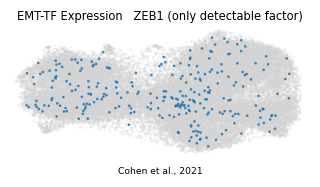

In [5]:
# categorical thresholded-expresser overlay: expressers (> upper-quartile of positive cells) colored
# over a grey manifold; consistent marker size across the two factors and the grey base.
xl = adata.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
def _vec(g):
    x = adata[:, g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in show:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in show}
order = sorted(show, key=lambda g: -int(sel[g].sum()))  # larger set drawn first
palette = ['tab:blue', 'tab:red']
colors = {g: palette[i] for i, g in enumerate(show)}
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(adata, size=12, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=12, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
if len(show) == 2:
    ttl = 'EMT-TF Expression   %s (early) \u00b7 %s (late)' % (show[0], show[1])
else:
    ttl = 'EMT-TF Expression   %s (only detectable factor)' % show[0]
ax.set_title(ttl, size=7.5)
ax.text(.5, -.14, 'Cohen et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_out, 'expression.pdf'), bbox_inches='tight'); plt.show()
for g in show:
    m = sel[g]
    print('%s: %.1f%% expressing; %d shown (upper quartile), mean pseudotime of shown = %.2f'
          % (g, (_vec(g)>0).mean()*100, int(m.sum()), tn[m].mean()))
print('EMT-TFs shown:', ' + '.join(show), '| saved expression.pdf')